# Universidad de Cundinamarca

## Introducción a Machine Learning
### Semana 8 — Comparación de algoritmos de clasificación

**Título del proyecto:** Clasificación supervisada con algoritmos de Machine Learning.

**Estudiante:** Gabriela Suesca Castillo  
**Docente:** Mónica Fonseca  
**Universidad:** Universidad de Cundinamarca  

---

### Dataset: IBM Telco Customer Churn

**Objetivo:** Comparar cinco algoritmos de clasificación supervisada para predecir si un cliente abandona una empresa de telecomunicaciones mediante la variable objetivo `Churn`.

**Modelos implementados:**
1. Decision Tree (Árbol de Decisión).
2. Random Forest.
3. Support Vector Machine (SVM).
4. K-Nearest Neighbors (K-NN).
5. Naive Bayes.

**Fuente de datos:** Repositorio público de IBM: `IBM/telco-customer-churn-on-icp4d`.

### Descripción del proyecto

Este proyecto busca implementar, entrenar y evaluar cinco algoritmos de clasificación supervisada utilizando el mismo conjunto de datos. Se comparará su desempeño mediante las métricas Accuracy, Precision, Recall y F1-score, así como las matrices de confusión.

Finalmente, se analizarán los resultados para identificar el modelo más adecuado para el problema de clasificación planteado.

> **Nota:** Ejecuta las celdas en orden. El notebook descarga el conjunto de datos desde el repositorio público de IBM y calcula los resultados durante la ejecución. Las conclusiones se elaborarán a partir de las métricas obtenidas.


## 1. Importar bibliotecas

Usaremos pandas y NumPy para manipular los datos, Matplotlib y Seaborn para las visualizaciones, y Scikit-learn para preparar, entrenar y evaluar los modelos.


In [12]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)


## 2. Cargar el conjunto de datos

El archivo contiene información demográfica, servicios contratados, facturación y la variable `Churn`, que indica si el cliente se retiró (`Yes`) o permaneció (`No`).


In [13]:
# URL del CSV publicado en el repositorio de IBM.
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
display(df.head())


Filas: 7,043 | Columnas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Exploración inicial

Revisamos los tipos de datos, los valores faltantes y la distribución de la variable objetivo. Esto permite conocer la estructura del conjunto antes de entrenar los modelos.


Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

,valores_faltantes
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


\nDistribución de Churn:


,cantidad
Churn,
No,5174
Yes,1869


,porcentaje
Churn,
No,73.46
Yes,26.54


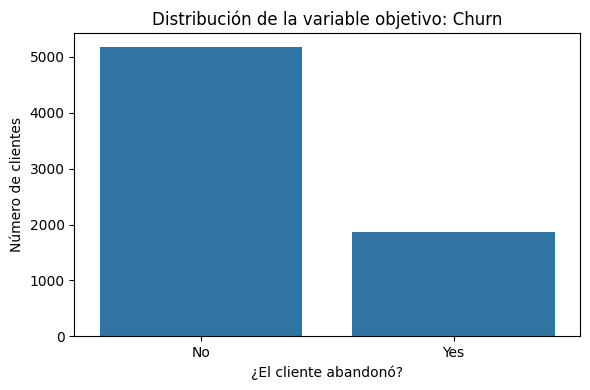

In [14]:
print("Información general:")
df.info()

print("\\nValores faltantes por columna:")
display(df.isna().sum().sort_values(ascending=False).to_frame("valores_faltantes"))

print("\\nDistribución de Churn:")
display(df["Churn"].value_counts().to_frame("cantidad"))
display((df["Churn"].value_counts(normalize=True) * 100).round(2).to_frame("porcentaje"))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Distribución de la variable objetivo: Churn")
plt.xlabel("¿El cliente abandonó?")
plt.ylabel("Número de clientes")
plt.tight_layout()
plt.show()


## 4. Preparación de los datos

- `Churn` será la variable objetivo.
- `customerID` se elimina porque es un identificador y no representa un patrón generalizable.
- `TotalCharges` puede venir como texto y contener espacios en blanco; lo convertimos a formato numérico.
- Las variables categóricas se codifican con One-Hot Encoding.
- Las variables numéricas se imputan si hiciera falta y se estandarizan. La estandarización es especialmente importante para SVM y K-NN.
- El preprocesamiento se ajusta dentro de un `Pipeline`, usando únicamente el conjunto de entrenamiento, para evitar fuga de información.


In [15]:
# Trabajamos sobre una copia para conservar el DataFrame original.
data = df.copy()

# TotalCharges puede contener cadenas vacías; se convierten en valores faltantes
# y luego a tipo numérico.
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")

# Quitamos el identificador del cliente.
data = data.drop(columns=["customerID"], errors="ignore")

# Convertimos la etiqueta objetivo a 0 = No y 1 = Yes.
data["Churn"] = data["Churn"].map({"No": 0, "Yes": 1})

# Separamos variables predictoras (X) y objetivo (y).
X = data.drop(columns=["Churn"])
y = data["Churn"]

# Identificamos automáticamente las columnas numéricas y categóricas.
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Variable objetivo: Churn (0 = No, 1 = Yes)")
print("Variables numéricas:", numeric_features)
print("Variables categóricas:", categorical_features)
print("Registros con objetivo faltante:", y.isna().sum())


Variable objetivo: Churn (0 = No, 1 = Yes)
Variables numéricas: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Variables categóricas: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Registros con objetivo faltante: 0


## 5. Dividir los datos en entrenamiento y prueba

Se utilizará una división de 80 % para entrenamiento y 20 % para prueba. `stratify=y` conserva aproximadamente la misma proporción de clientes que abandonaron y que permanecieron en ambos subconjuntos.

Los cinco modelos utilizarán exactamente la misma división.


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Registros de entrenamiento: {X_train.shape[0]:,}")
print(f"Registros de prueba: {X_test.shape[0]:,}")
print("\\nProporción de Churn en entrenamiento:")
display(y_train.value_counts(normalize=True).mul(100).round(2).to_frame("porcentaje"))
print("\\nProporción de Churn en prueba:")
display(y_test.value_counts(normalize=True).mul(100).round(2).to_frame("porcentaje"))


Registros de entrenamiento: 5,634
Registros de prueba: 1,409
\nProporción de Churn en entrenamiento:


,porcentaje
Churn,
0,73.46
1,26.54


\nProporción de Churn en prueba:


,porcentaje
Churn,
0,73.46
1,26.54


## 6. Definir el preprocesamiento y los cinco algoritmos

El preprocesamiento se incorpora a cada modelo mediante un `Pipeline`. Así, todos reciben los mismos datos y se evita que la información del conjunto de prueba influya en el ajuste.

Naive Bayes se implementa como Gaussian Naive Bayes, una variante apropiada como punto de partida cuando hay características numéricas continuas.


In [17]:
# Preprocesamiento común:
# - Numéricas: imputación por mediana y estandarización.
# - Categóricas: imputación por valor más frecuente y One-Hot Encoding.
# sparse_output=False produce una matriz densa, necesaria para GaussianNB.
preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features),
        ("cat", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), categorical_features)
    ],
    remainder="drop"
)

models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        max_depth=8,
        class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1
    ),
    "SVM": SVC(
        kernel="rbf",
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "K-NN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB()
}

print("Modelos definidos:", ", ".join(models.keys()))


Modelos definidos: Decision Tree, Random Forest, SVM, K-NN, Naive Bayes


## 7. Entrenar y evaluar los modelos

Para `Precision`, `Recall` y `F1-score` consideramos como clase positiva `Churn = 1` (clientes que abandonaron). Esto es importante porque la empresa querría identificar a los clientes con riesgo de irse, no solamente acertar la clase mayoritaria.

- **Accuracy:** proporción total de predicciones correctas.
- **Precision:** de los clientes que el modelo predijo que se irían, cuántos efectivamente se fueron.
- **Recall:** de todos los clientes que se fueron, cuántos detectó el modelo.
- **F1-score:** equilibrio entre Precision y Recall.

Se usa `zero_division=0` para evitar errores si algún modelo no predice casos positivos.


In [18]:
trained_models = {}
predictions = {}
results = []

for name, estimator in models.items():
    # Cada modelo tiene su propio preprocesador, ajustado solo con entrenamiento.
    pipeline = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    trained_models[name] = pipeline
    predictions[name] = y_pred

    results.append({
        "Modelo": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Churn=1)": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Recall (Churn=1)": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "F1-score (Churn=1)": f1_score(y_test, y_pred, pos_label=1, zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values(
    by="F1-score (Churn=1)", ascending=False
).reset_index(drop=True)

display(results_df.style.format({
    "Accuracy": "{:.3f}",
    "Precision (Churn=1)": "{:.3f}",
    "Recall (Churn=1)": "{:.3f}",
    "F1-score (Churn=1)": "{:.3f}"
}))


,Modelo,Accuracy,Precision (Churn=1),Recall (Churn=1),F1-score (Churn=1)
0,SVM,0.744,0.512,0.773,0.616
1,Decision Tree,0.735,0.501,0.773,0.608
2,Naive Bayes,0.695,0.459,0.837,0.593
3,K-NN,0.764,0.553,0.575,0.564
4,Random Forest,0.783,0.618,0.476,0.538


## 8. Comparación visual de métricas

La siguiente gráfica permite comparar el desempeño de los cinco algoritmos. No hay que interpretar una métrica de forma aislada: por ejemplo, un modelo puede tener Accuracy alto pero detectar pocos clientes que realmente abandonan.


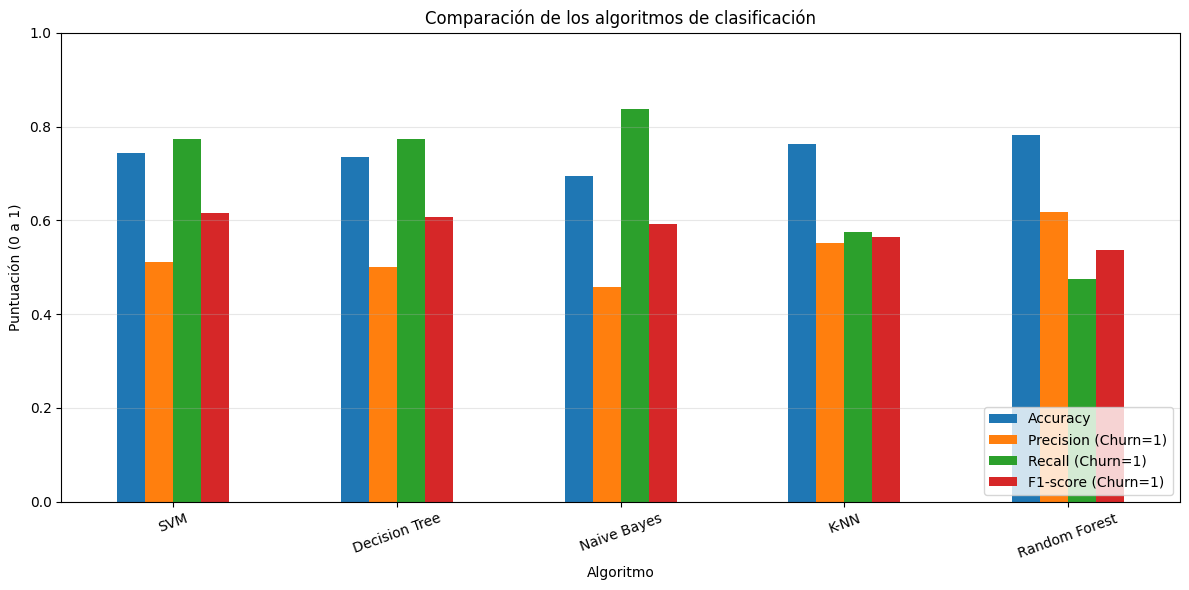

In [19]:
metrics_to_plot = [
    "Accuracy", "Precision (Churn=1)", "Recall (Churn=1)", "F1-score (Churn=1)"
]

plot_df = results_df.set_index("Modelo")[metrics_to_plot]
ax = plot_df.plot(kind="bar", figsize=(12, 6), ylim=(0, 1), rot=20)
ax.set_title("Comparación de los algoritmos de clasificación")
ax.set_ylabel("Puntuación (0 a 1)")
ax.set_xlabel("Algoritmo")
ax.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 9. Matrices de confusión

La matriz de confusión compara las etiquetas reales con las predichas. En este problema:
- **Verdadero negativo (TN):** cliente que permaneció y fue clasificado como tal.
- **Falso positivo (FP):** cliente que permaneció, pero el modelo predijo que se iría.
- **Falso negativo (FN):** cliente que se fue, pero el modelo no lo detectó.
- **Verdadero positivo (TP):** cliente que se fue y fue detectado correctamente.

Los falsos negativos pueden ser especialmente relevantes si el objetivo es identificar clientes en riesgo para ofrecer acciones de retención.


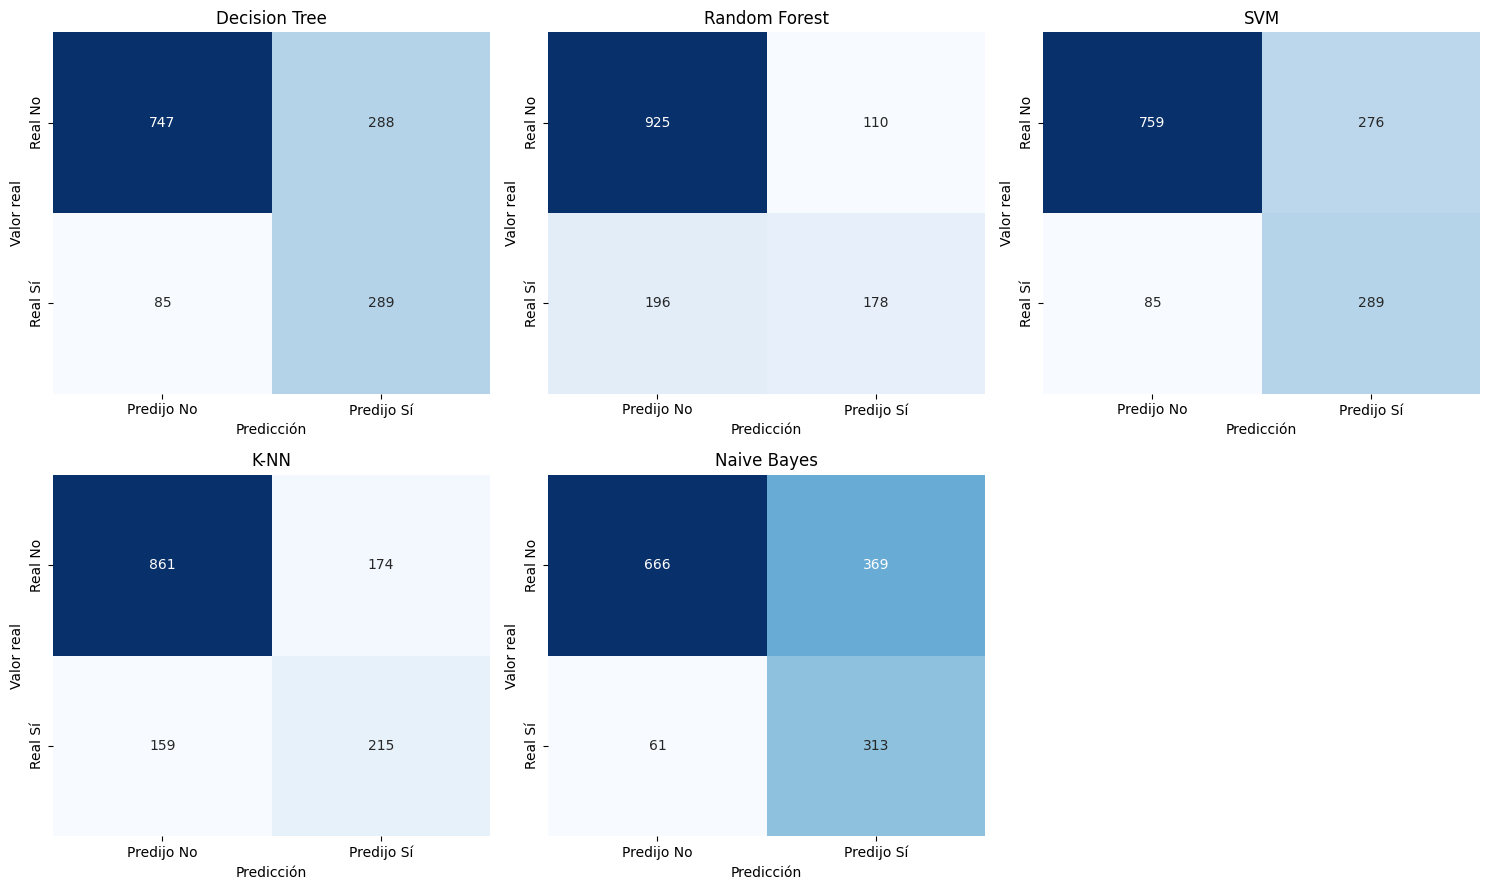

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

for i, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["Predijo No", "Predijo Sí"],
        yticklabels=["Real No", "Real Sí"],
        ax=axes[i]
    )
    axes[i].set_title(name)
    axes[i].set_xlabel("Predicción")
    axes[i].set_ylabel("Valor real")

# Ocultamos el sexto panel, ya que solo hay cinco modelos.
axes[-1].axis("off")
plt.tight_layout()
plt.show()


## 10. Reporte detallado por modelo

Este reporte incluye Precision, Recall y F1-score por clase, además de los promedios. Es útil para revisar si el modelo se comporta de forma distinta entre clientes que abandonan y clientes que permanecen.


In [21]:
for name, y_pred in predictions.items():
    print("=" * 75)
    print(f"MODELO: {name}")
    print(classification_report(
        y_test, y_pred,
        labels=[0, 1],
        target_names=["No abandona", "Sí abandona"],
        zero_division=0,
        digits=3
    ))


MODELO: Decision Tree
              precision    recall  f1-score   support

 No abandona      0.898     0.722     0.800      1035
 Sí abandona      0.501     0.773     0.608       374

    accuracy                          0.735      1409
   macro avg      0.699     0.747     0.704      1409
weighted avg      0.792     0.735     0.749      1409

MODELO: Random Forest
              precision    recall  f1-score   support

 No abandona      0.825     0.894     0.858      1035
 Sí abandona      0.618     0.476     0.538       374

    accuracy                          0.783      1409
   macro avg      0.722     0.685     0.698      1409
weighted avg      0.770     0.783     0.773      1409

MODELO: SVM
              precision    recall  f1-score   support

 No abandona      0.899     0.733     0.808      1035
 Sí abandona      0.512     0.773     0.616       374

    accuracy                          0.744      1409
   macro avg      0.705     0.753     0.712      1409
weighted avg      

## 11. Selección preliminar del mejor modelo

Como criterio inicial, seleccionamos el modelo con mayor F1-score para la clase positiva (`Churn=1`). F1-score permite equilibrar Precision y Recall, aunque la decisión final debe considerar el objetivo del negocio: si es más importante detectar a la mayor cantidad de clientes en riesgo, puede priorizarse Recall.

La selección automática que aparece a continuación es una recomendación basada en esta métrica, no una afirmación de que el modelo sea universalmente mejor.


In [22]:
best_row = results_df.iloc[0]
print(f"Modelo con mayor F1-score para Churn=1: {best_row['Modelo']}")
print(f"F1-score: {best_row['F1-score (Churn=1)']:.3f}")
print(f"Precision: {best_row['Precision (Churn=1)']:.3f}")
print(f"Recall: {best_row['Recall (Churn=1)']:.3f}")
print(f"Accuracy: {best_row['Accuracy']:.3f}")

print("\\nInterpretación:")
print(
    "La selección se basa en el F1-score de los clientes que abandonan. "
    "Antes de concluir, compara también Precision y Recall y revisa la matriz de confusión. "
    "Si el negocio necesita detectar la mayor cantidad posible de clientes en riesgo, "
    "un Recall mayor puede ser más conveniente aunque genere más falsas alarmas."
)


Modelo con mayor F1-score para Churn=1: SVM
F1-score: 0.616
Precision: 0.512
Recall: 0.773
Accuracy: 0.744
\nInterpretación:
La selección se basa en el F1-score de los clientes que abandonan. Antes de concluir, compara también Precision y Recall y revisa la matriz de confusión. Si el negocio necesita detectar la mayor cantidad posible de clientes en riesgo, un Recall mayor puede ser más conveniente aunque genere más falsas alarmas.


## Referencias

- IBM, repositorio público del conjunto de datos Telco Customer Churn: https://github.com/IBM/telco-customer-churn-on-icp4d
- IBM, tutorial de predicción de abandono de clientes de telecomunicaciones: https://www.ibm.com/docs/en/ws-and-kc?topic=tutorials-predict-telecommunications-churn
- Scikit-learn, documentación oficial: https://scikit-learn.org/stable/
